In [1]:
from scipy import stats
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
#spatial decoding
 #np.array([61.4,60.9,62.8,61.7,55.6, 62.1, 65.3, 64.5, 54.2, 57.4])
 #np.array([61.3,62.1,58.2,64.1,62.6, 58.1, 61.9, 62.8, 59.7, 58.1])
 #np.array([60.1,61.1,64.2,63.7,60.3, 56.7, 62.1, 61.5, 57.4, 62]) 

#create data
#x_soc = np.array([53.3,60.2,63.2,62.1,68.6, 56.1, 57.8, 64.1, 57.1, 55.8]) #decoding
x_soc = np.array([61.4,60.9,62.8,61.7,55.6, 62.1, 65.3, 64.5, 54.2, 57.4])#decoding
y_soc = np.array([0,0,1,0,1,0,0,0,0,1.9]) #freezing

#x_mockSFC = np.array([56.0,51.1,63.4,60.1,64.35, 58.4,  60.3, 55.9,  58.4, 52.7]) #decoding
x_mockSFC = np.array([61.3,62.1,58.2,64.1,62.6, 58.1, 61.9, 62.8, 59.7, 58.1]) #decoding
y_mockSFC = np.array([0,0,0,0,1.3,1,0,0,0,1.4]) #freezing

x = np.subtract(x_mockSFC, x_soc)
y = np.subtract(y_mockSFC, y_soc)
flag = ['n' for i in range(len(x))]
#y = np.absolute(y)

print(x)
print(y)

print(stats.pearsonr(x, y))
print(stats.spearmanr(x, y))
#print(np.corrcoef(x,y))
print(np.mean(y))

[-0.1  1.2 -4.6  2.4  7.  -4.  -3.4 -1.7  5.5  0.7]
[ 0.   0.  -1.   0.   0.3  1.   0.   0.   0.  -0.5]
PearsonRResult(statistic=0.1343930285070788, pvalue=0.7112677573237665)
SpearmanrResult(correlation=0.2526318345396, pvalue=0.4813083005379245)
-0.019999999999999997


In [5]:
#spatial decoding
 #np.array([61.4,60.9,62.8,61.7,55.6, 62.1, 65.3, 64.5, 54.2, 57.4])
 #np.array([61.3,62.1,58.2,64.1,62.6, 58.1, 61.9, 62.8, 59.7, 58.1])
 #np.array([60.1,61.1,64.2,63.7,60.3, 56.7, 62.1, 61.5, 57.4, 62]) 

#x2_soc = np.array([53.3,60.2,63.2,62.1,68.6, 56.1, 57.8, 64.1, 57.1, 55.8]) #decoding
x2_soc = np.array([61.4,60.9,62.8,61.7,55.6, 62.1, 65.3, 64.5, 54.2, 57.4]) #decoding
y2_soc = np.array([1,2.7,0,0,1,0,0,0,1,0]) #freezing

#x2_mockExt = np.array([55.3,60.4,64.7,57.4,65.6, 60.1, 59.8, 65.1,  56.4, 52.7]) #decoding
x2_mockExt = np.array([60.1,61.1,64.2,63.7,60.3, 56.7, 62.1, 61.5, 57.4, 62]) #decoding
y2_mockExt = np.array([0,1,1,0,0,1,0,0,1.9,1]) #freezing


x2 = np.subtract(x2_mockExt, x2_soc)
y2 = np.subtract(y2_mockExt, y2_soc)
flag_2 = ['y' for i in range(len(x2))]
#y = np.absolute(y)

print(x2)
print(y2)
print('mean:')
print(np.mean(x2))
print(np.mean(y2))

#print('Pearson\'s correlation:')
#print(np.corrcoef(x2,y2))

print(stats.pearsonr(x2, y2))
print(stats.spearmanr(x2, y2))

[-1.3  0.2  1.4  2.   4.7 -5.4 -3.2 -3.   3.2  4.6]
[-1.  -1.7  1.   0.  -1.   1.   0.   0.   0.9  1. ]
mean:
0.320000000000001
0.019999999999999973
PearsonRResult(statistic=-0.010545285167230637, pvalue=0.9769347537362588)
SpearmanrResult(correlation=-0.031164899666948572, pvalue=0.931892956705848)


In [6]:
x_df = list(x)
x_df.extend(x2)
y_df = list(y)
y_df.extend(y2)
flag.extend(flag_2)

dataframe = pd.DataFrame(list(zip(x_df, y_df, flag)),columns=['x','y','r3r4'])

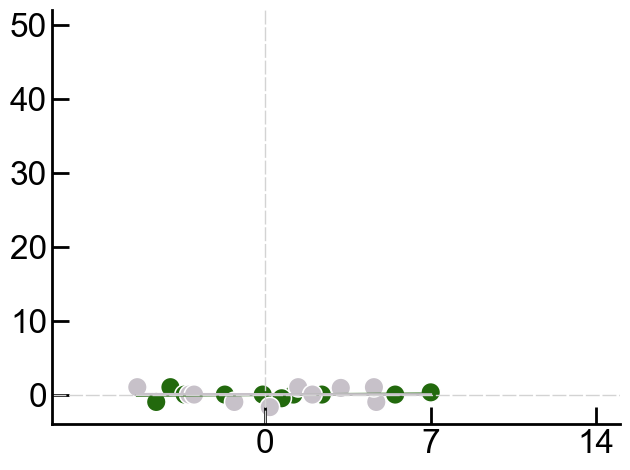

In [11]:
colors = ["#22690d","#c7c1c9"]

fig, ax = plt.subplots()  # create figure and axes

# plot on ax (Axes) object
sns.scatterplot(data=dataframe, x='x', y='y',hue='r3r4',palette=colors,s=200)

#mfc='none'
#obtain m (slope) and b(intercept) of linear regression line
m, b = np.polyfit(x, y, 1)
m2, b2 = np.polyfit(x2,y2,1)

#add linear regression line to scatterplot 
#ax.plot(x, m*x+b, color='#144e96')
l_reg_line = np.array([min(x.min(),x2.min()),max(x.max(),x2.max())])
ax.plot(l_reg_line, m*l_reg_line+b, color=colors[0], linewidth=2)
ax.plot(l_reg_line, m2*l_reg_line+b2, color=colors[1], linewidth=2)

ax.set_ylim([-4,52])
ax.set_yticks([0,10,20,30,40,50], fontname='Arial')
ax.set_yticklabels(['0','10','20','30','40','50'],fontname='Arial')

ax.set_xlim([-9,15])
ax.set_xticks([0,7,14], fontname='Arial')
ax.set_xticklabels(['0','7','14'],fontname='Arial')

sns.despine(top=True, right=True, left=False, bottom=False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.set_xlabel('Δ Decoding accuracy', fontsize=22)
ax.set_xlabel('', fontsize=22)

ax.set_ylabel('Δ Freezing (sec)', fontsize=22)
ax.set_ylabel('', fontsize=22)

plt.axhline(y=0,linewidth=1, color='lightgrey',ls='--', dashes=(10, 2))
plt.axvline(x=0,linewidth=1, color='lightgrey',ls='--', dashes=(10, 2))



#ax.tick_params(axis='both', which='major', )
ax.tick_params(axis='both', which='major', direction='in',length=12, labelsize=24, width=2)

handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles,['Recall 1&2', 'Recall 3&4'], fontsize = 18, frameon=False, loc='upper left')
ax.get_legend().remove()


plt.tight_layout()
fig.tight_layout()
fig.savefig("SpatialDecoding_FreezingControls.jpg",dpi=600)
plt.savefig('SpatialDecoding_FreezingControls.eps', format='eps', dpi=600)
